# Digital Image Processing — Lab Task 03
## Image Enhancement and Intensity Transformations

**Name:** Ubaidullah  
**Roll No:** 2024-SE-17  
**Class:** 5th Semester, Software Engineering (Session 2024-28), UAJK  
**Lab Instructor:** Engr. Fahad Nisar

## 0. Setup: imports, image loading and numeric safety

In [29]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100

def show_pair(images, titles, figsize=None):
    """Display images side by side with the fixed grayscale range 0-255."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=figsize or (4.2 * n, 4.2))
    axes = np.atleast_1d(axes)
    for ax, pic, name in zip(axes, images, titles):
        ax.imshow(pic, cmap="gray", vmin=0, vmax=255)
        ax.set_title(name)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

def table(header, rows):
    """Print a simple text table for dry-run verification."""
    widths = [max(len(str(x)) for x in col) for col in zip(header, *rows)]
    line = lambda r: " | ".join(str(x).rjust(w) for x, w in zip(r, widths))
    print(line(header)); print("-+-".join("-" * w for w in widths))
    for r in rows: print(line(r))

In [3]:
# Load the personally selected image as 8-bit grayscale and validate it
img = cv.imread("image.png", cv.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("Please place image.png next to this notebook")
assert img.dtype == np.uint8 and img.ndim == 2, "Expected an 8-bit grayscale image"
assert img.shape[0] >= 300 and img.shape[1] >= 300, "Image must be at least 300 x 300"

original = img.copy()          # keep the original unchanged
img.flags.writeable = False    # any accidental in-place edit now raises an error

print("Shape :", img.shape)
print("dtype :", img.dtype)
print("Min   :", img.min())
print("Max   :", img.max())

Shape : (300, 300)
dtype : uint8
Min   : 0
Max   : 255


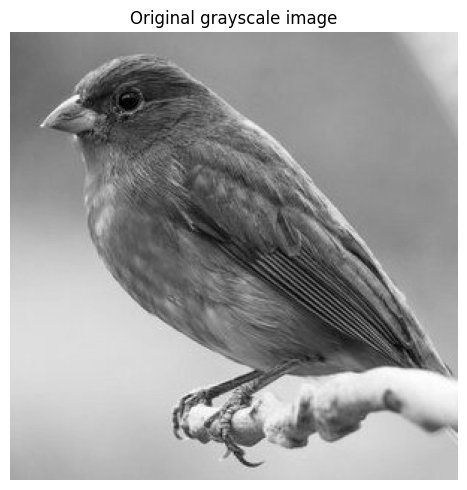

In [4]:
show_pair([img], ["Original grayscale image"], figsize=(5, 5))

## 1. Brightness adjustment

**Dry run** — pixels `[30, 80, 128, 180, 240]`, β = +40 and −40. Raw value → clipped → final `uint8`.

In [5]:
px = np.array([30, 80, 128, 180, 240])
rows = []
for r in px:
    up, dn = int(r) + 40, int(r) - 40
    rows.append([r, up, min(255, max(0, up)), dn, min(255, max(0, dn))])
table(["r", "r+40 raw", "final(+40)", "r-40 raw", "final(-40)"], rows)

# Python verification with the safe NumPy recipe
chk_up = np.clip(px.astype(np.int16) + 40, 0, 255).astype(np.uint8)
chk_dn = np.clip(px.astype(np.int16) - 40, 0, 255).astype(np.uint8)
print("\nNumPy +40:", chk_up)
print("NumPy -40:", chk_dn)
print("Unsafe uint8 +40 (wraps!):", px.astype(np.uint8) + np.uint8(40))

  r | r+40 raw | final(+40) | r-40 raw | final(-40)
----+----------+------------+----------+-----------
 30 |       70 |         70 |      -10 |          0
 80 |      120 |        120 |       40 |         40
128 |      168 |        168 |       88 |         88
180 |      220 |        220 |      140 |        140
240 |      280 |        255 |      200 |        200

NumPy +40: [ 70 120 168 220 255]
NumPy -40: [  0  40  88 140 200]
Unsafe uint8 +40 (wraps!): [ 70 120 168 220  24]


**Image task** — brighter (+40) and darker (−40) using a wider type (`int16`), then clip, then `uint8`.

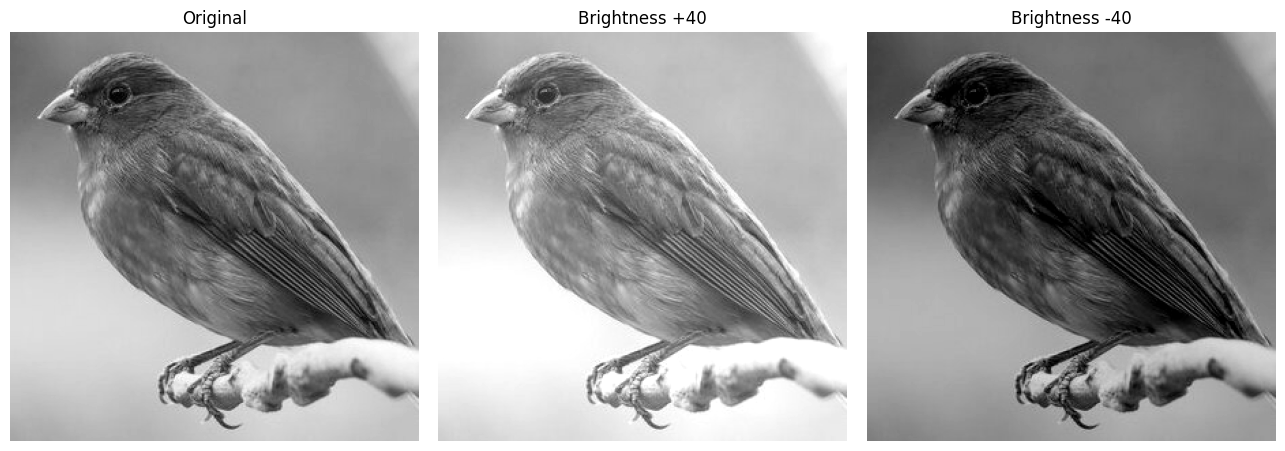

Original mean: 147.03 | +40 mean: 186.18 | -40 mean: 107.32
Pixels clipped to 255 by +40: 9199
Pixels clipped to 0 by -40  : 1890


In [6]:
bright = np.clip(img.astype(np.int16) + 40, 0, 255).astype(np.uint8)
dark   = np.clip(img.astype(np.int16) - 40, 0, 255).astype(np.uint8)
show_pair([img, bright, dark], ["Original", "Brightness +40", "Brightness -40"], figsize=(13, 4.4))
print("Original mean:", round(img.mean(), 2), "| +40 mean:", round(bright.mean(), 2), "| -40 mean:", round(dark.mean(), 2))
print("Pixels clipped to 255 by +40:", int((img.astype(np.int16) + 40 > 255).sum()))
print("Pixels clipped to 0 by -40  :", int((img.astype(np.int16) - 40 < 0).sum()))

**+40 with nested loops**, verified against the NumPy result.

In [7]:
height, width = img.shape
bright_loop = np.zeros_like(img)
for row in range(height):
    for col in range(width):
        pixel = int(img[row, col])            # int() avoids uint8 wrap-around
        new_pixel = pixel + 40
        bright_loop[row, col] = min(255, max(0, new_pixel))

print("Loop result identical to NumPy result:", np.array_equal(bright_loop, bright))

Loop result identical to NumPy result: True


## 2. Linear contrast from zero: s = αr + β  (α = 1.5, β = 0)

**Dry run** — pixels `[30, 80, 128, 180, 240]`.

In [8]:
alpha, beta = 1.5, 0
raw = alpha * px.astype(np.float32) + beta
final = np.clip(raw, 0, 255).astype(np.uint8)       # clip, then truncate
table(["r", "1.5*r raw", "clipped", "final uint8", "saturated?"],
      [[r, v, min(255, v), f, "YES" if v > 255 else "no"] for r, v, f in zip(px, raw, final)])

  r | 1.5*r raw | clipped | final uint8 | saturated?
----+-----------+---------+-------------+-----------
 30 |      45.0 |    45.0 |          45 |         no
 80 |     120.0 |   120.0 |         120 |         no
128 |     192.0 |   192.0 |         192 |         no
180 |     270.0 |     255 |         255 |        YES
240 |     360.0 |     255 |         255 |        YES


**Image task** — compare brightness and highlight clipping with the original.

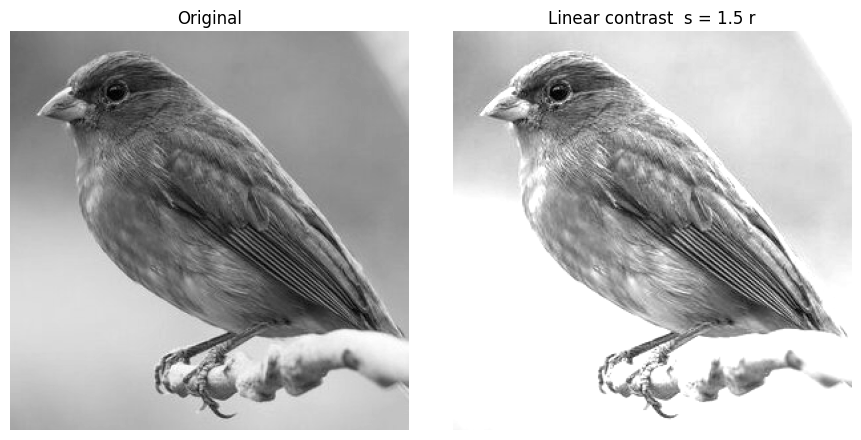

Mean original: 147.03 | Mean 1.5r: 202.21
Saturated (clipped at 255) pixels: 30383  (33.76 % of the image)


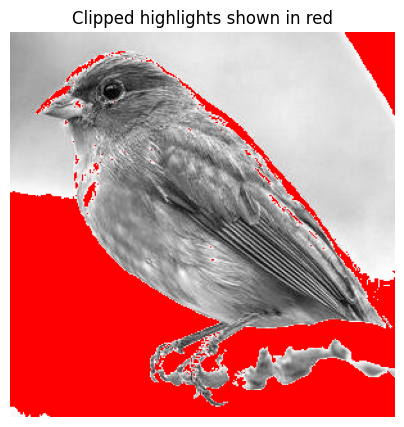

In [9]:
lin = np.clip(1.5 * img.astype(np.float32) + 0, 0, 255).astype(np.uint8)
show_pair([img, lin], ["Original", "Linear contrast  s = 1.5 r"], figsize=(9, 4.4))
sat = int((1.5 * img.astype(np.float32) > 255).sum())
print("Mean original:", round(img.mean(), 2), "| Mean 1.5r:", round(lin.mean(), 2))
print(f"Saturated (clipped at 255) pixels: {sat}  ({100 * sat / img.size:.2f} % of the image)")

# Highlight the clipped region in the image
mask = (1.5 * img.astype(np.float32) > 255)
overlay = cv.cvtColor(lin, cv.COLOR_GRAY2RGB)
overlay[mask] = [255, 0, 0]
plt.figure(figsize=(5, 5)); plt.imshow(overlay); plt.title("Clipped highlights shown in red"); plt.axis("off"); plt.show()

## 3. Contrast centered at 128: s = (r − 128)α + 128  (α = 1.5 and 0.5)

**Dry run** — pixels `[30, 80, 128, 180, 240]`.

In [10]:
rows = []
for a in (1.5, 0.5):
    print(f"alpha = {a}")
    rows = []
    for r in px:
        d = int(r) - 128
        m = d * a
        s = m + 128
        rows.append([r, d, m, s, int(np.clip(s, 0, 255))])
    table(["r", "r-128", f"x{a}", "+128 raw", "final"], rows)
    print()
cen15 = np.clip((px.astype(np.float32) - 128) * 1.5 + 128, 0, 255).astype(np.uint8)
cen05 = np.clip((px.astype(np.float32) - 128) * 0.5 + 128, 0, 255).astype(np.uint8)
print("NumPy check  alpha=1.5:", cen15)
print("NumPy check  alpha=0.5:", cen05)
print("At r = 128 the term (r-128) is 0, so the output stays 128 for every alpha (the pivot).")

alpha = 1.5
  r | r-128 |   x1.5 | +128 raw | final
----+-------+--------+----------+------
 30 |   -98 | -147.0 |    -19.0 |     0
 80 |   -48 |  -72.0 |     56.0 |    56
128 |     0 |    0.0 |    128.0 |   128
180 |    52 |   78.0 |    206.0 |   206
240 |   112 |  168.0 |    296.0 |   255

alpha = 0.5
  r | r-128 |  x0.5 | +128 raw | final
----+-------+-------+----------+------
 30 |   -98 | -49.0 |     79.0 |    79
 80 |   -48 | -24.0 |    104.0 |   104
128 |     0 |   0.0 |    128.0 |   128
180 |    52 |  26.0 |    154.0 |   154
240 |   112 |  56.0 |    184.0 |   184

NumPy check  alpha=1.5: [  0  56 128 206 255]
NumPy check  alpha=0.5: [ 79 104 128 154 184]
At r = 128 the term (r-128) is 0, so the output stays 128 for every alpha (the pivot).


**Image task** — compare both centered results with linear contrast from zero.

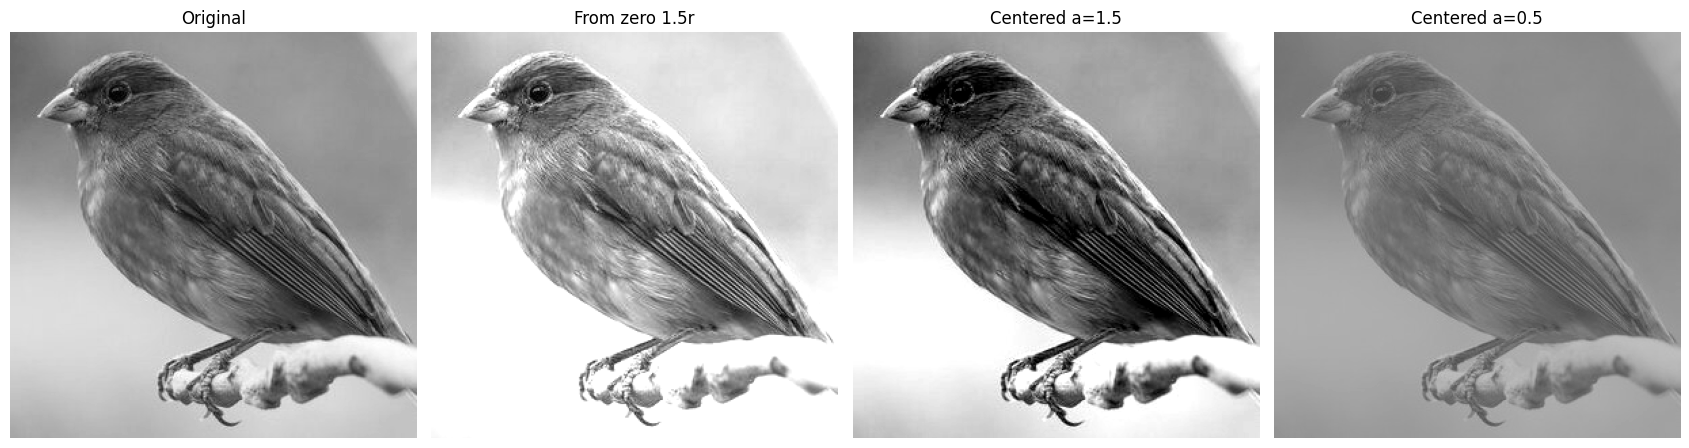

Original      mean= 147.03  std= 52.35  min=  0  max=255
1.5 r         mean= 202.21  std= 58.39  min=  0  max=255
Centered 1.5  mean= 155.16  std= 74.89  min=  0  max=255
Centered 0.5  mean= 137.27  std= 26.18  min= 64  max=191


In [11]:
c15 = np.clip((img.astype(np.float32) - 128) * 1.5 + 128, 0, 255).astype(np.uint8)
c05 = np.clip((img.astype(np.float32) - 128) * 0.5 + 128, 0, 255).astype(np.uint8)
show_pair([img, lin, c15, c05],
          ["Original", "From zero 1.5r", "Centered a=1.5", "Centered a=0.5"], figsize=(17, 4.4))
for name, pic in [("Original", img), ("1.5 r", lin), ("Centered 1.5", c15), ("Centered 0.5", c05)]:
    print(f"{name:13s} mean={pic.mean():7.2f}  std={pic.std():6.2f}  min={pic.min():3d}  max={pic.max():3d}")

## 4. Image negative: s = 255 − r

**Dry run** — pixels `[30, 80, 128, 180, 240]`; apply the negative twice.

In [12]:
neg_px = 255 - px.astype(np.uint8)
neg_neg = 255 - neg_px
table(["r", "255-r", "255-(255-r)", "same as original?"],
      [[r, n, nn, "yes" if r == nn else "NO"] for r, n, nn in zip(px, neg_px, neg_neg)])
print("Double negative equals original:", np.array_equal(neg_neg, px))

  r | 255-r | 255-(255-r) | same as original?
----+-------+-------------+------------------
 30 |   225 |          30 |               yes
 80 |   175 |          80 |               yes
128 |   127 |         128 |               yes
180 |    75 |         180 |               yes
240 |    15 |         240 |               yes
Double negative equals original: True


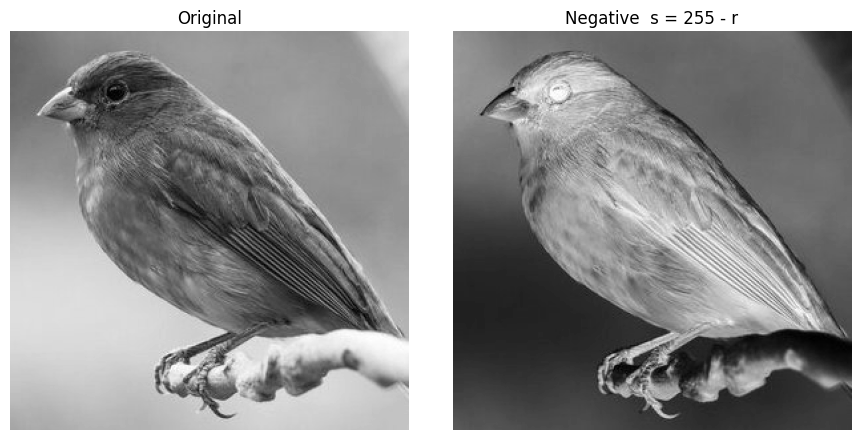

Double negative restores the image exactly: True


In [13]:
negative = 255 - img                   # stays inside 0-255 for uint8, so no overflow
show_pair([img, negative], ["Original", "Negative  s = 255 - r"], figsize=(9, 4.4))
print("Double negative restores the image exactly:", np.array_equal(255 - negative, img))

**Where it helps:** bright details on a very dark background (for example white lesions or bone structures in a dark medical/X-ray image) are easier to see as dark marks on a light background, which matches how the eye reads printed text.

## 5. Gamma correction: s = 255 (r/255)^γ  (γ = 0.5 and 2.0)

**Dry run** — pixels `[0, 64, 128, 192, 255]`; full precision, truncate only at the end.

In [14]:
g_px = np.array([0, 64, 128, 192, 255])
for g in (0.5, 2.0):
    print(f"gamma = {g}")
    rows = []
    for r in g_px:
        n = r / 255.0
        p = n ** g
        s = 255 * p
        rows.append([r, f"{n:.6f}", f"{p:.6f}", f"{s:.4f}", int(np.clip(s, 0, 255)), int(round(s))])
    table(["r", "r/255", "power", "x255", "truncated", "rounded"], rows)
    print()
gam05 = np.clip(255 * np.power(g_px.astype(np.float32) / 255.0, 0.5), 0, 255).astype(np.uint8)
gam20 = np.clip(255 * np.power(g_px.astype(np.float32) / 255.0, 2.0), 0, 255).astype(np.uint8)
print("NumPy check  gamma=0.5:", gam05)
print("NumPy check  gamma=2.0:", gam20)
print("0 and 255 fixed:", gam05[0], gam05[-1], gam20[0], gam20[-1])

gamma = 0.5
  r |    r/255 |    power |     x255 | truncated | rounded
----+----------+----------+----------+-----------+--------
  0 | 0.000000 | 0.000000 |   0.0000 |         0 |       0
 64 | 0.250980 | 0.500979 | 127.7498 |       127 |     128
128 | 0.501961 | 0.708492 | 180.6654 |       180 |     181
192 | 0.752941 | 0.867722 | 221.2691 |       221 |     221
255 | 1.000000 | 1.000000 | 255.0000 |       255 |     255

gamma = 2.0
  r |    r/255 |    power |     x255 | truncated | rounded
----+----------+----------+----------+-----------+--------
  0 | 0.000000 | 0.000000 |   0.0000 |         0 |       0
 64 | 0.250980 | 0.062991 |  16.0627 |        16 |      16
128 | 0.501961 | 0.251965 |  64.2510 |        64 |      64
192 | 0.752941 | 0.566920 | 144.5647 |       144 |     145
255 | 1.000000 | 1.000000 | 255.0000 |       255 |     255

NumPy check  gamma=0.5: [  0 127 180 221 255]
NumPy check  gamma=2.0: [  0  16  64 144 255]
0 and 255 fixed: 0 255 0 255


**Image task** — compare the effect on dark regions and confirm that 0 and 255 are fixed.

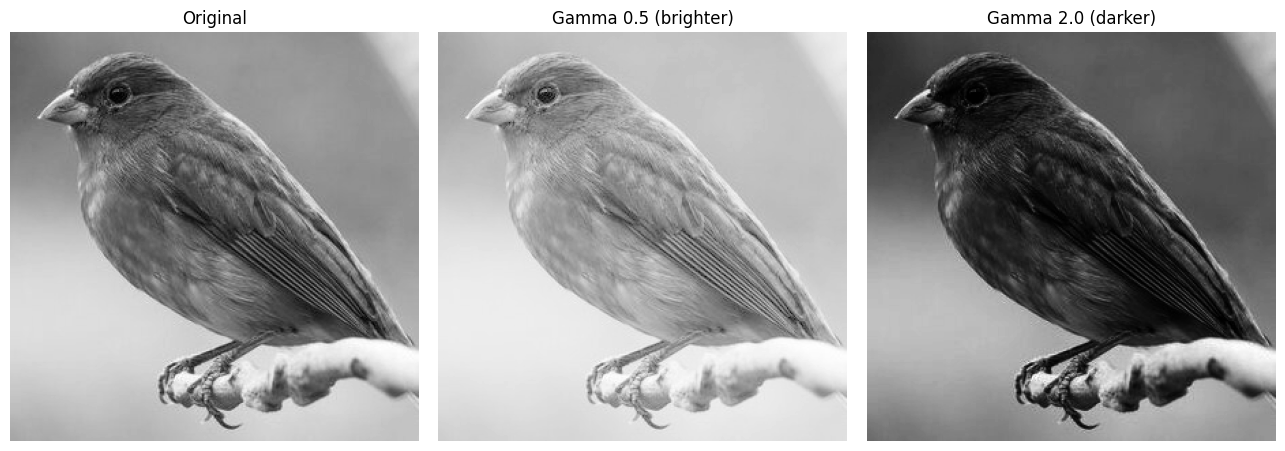

gamma 0.5 maps 0, 255 -> [  0 255]
gamma 2.0 maps 0, 255 -> [  0 255]
Mean of originally dark pixels (<60): 41.43 -> gamma 0.5: 100.12 | gamma 2.0: 7.03


In [15]:
def gamma_correct(image, g):
    return np.clip(255 * np.power(image.astype(np.float32) / 255.0, g), 0, 255).astype(np.uint8)

g05 = gamma_correct(img, 0.5)
g20 = gamma_correct(img, 2.0)
show_pair([img, g05, g20], ["Original", "Gamma 0.5 (brighter)", "Gamma 2.0 (darker)"], figsize=(13, 4.4))

lut_in = np.array([0, 255], dtype=np.uint8)
print("gamma 0.5 maps 0, 255 ->", gamma_correct(lut_in, 0.5))
print("gamma 2.0 maps 0, 255 ->", gamma_correct(lut_in, 2.0))
dark_region = img < 60
print("Mean of originally dark pixels (<60):", round(img[dark_region].mean(), 2),
      "-> gamma 0.5:", round(g05[dark_region].mean(), 2),
      "| gamma 2.0:", round(g20[dark_region].mean(), 2))

## 6. Grayscale histogram

**Dry run** — `A = [[0, 50, 50, 100], [100, 150, 200, 255]]`.

In [16]:
A = np.array([[0, 50, 50, 100], [100, 150, 200, 255]], dtype=np.uint8)
vals, counts = np.unique(A, return_counts=True)
total = A.size
table(["intensity", "frequency", "probability"],
      [[v, c, f"{c}/{total} = {c / total:.3f}"] for v, c in zip(vals, counts)])
print("Total pixel count:", total, "| probabilities sum to", (counts / total).sum())
print("Histogram of A (256 bins) nonzero entries:", {int(i): int(h) for i, h in enumerate(np.histogram(A, bins=256, range=(0, 256))[0]) if h})
B = np.array([[100, 255, 0, 50], [200, 50, 150, 100]], dtype=np.uint8)   # same pixels, different positions
print("Rearranged image has the same histogram:",
      np.array_equal(np.histogram(A, 256, (0, 256))[0], np.histogram(B, 256, (0, 256))[0]))

intensity | frequency | probability
----------+-----------+------------
        0 |         1 | 1/8 = 0.125
       50 |         2 | 2/8 = 0.250
      100 |         2 | 2/8 = 0.250
      150 |         1 | 1/8 = 0.125
      200 |         1 | 1/8 = 0.125
      255 |         1 | 1/8 = 0.125
Total pixel count: 8 | probabilities sum to 1.0
Histogram of A (256 bins) nonzero entries: {0: 1, 50: 2, 100: 2, 150: 1, 200: 1, 255: 1}
Rearranged image has the same histogram: True


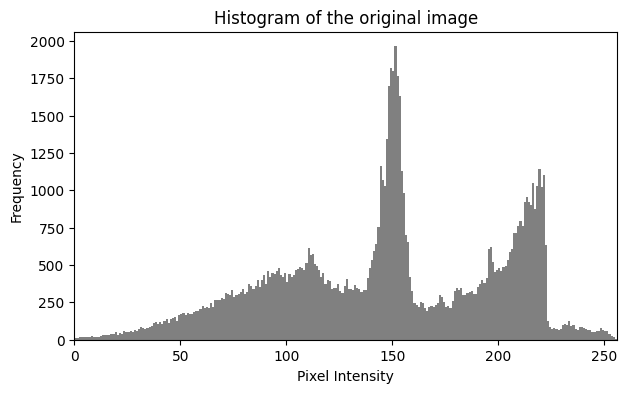

Mean intensity: 147.03 | Median: 149.0 | Std: 52.35


In [17]:
plt.figure(figsize=(7, 4))
plt.hist(img.ravel(), bins=256, range=(0, 256), color="gray")
plt.xlabel("Pixel Intensity"); plt.ylabel("Frequency"); plt.title("Histogram of the original image")
plt.xlim(0, 256); plt.show()
print("Mean intensity:", round(img.mean(), 2), "| Median:", np.median(img), "| Std:", round(img.std(), 2))

**Interpretation:** most pixels form one wide hump between about 90 and 210 (the paper and background, spread out because the lighting falls off across the page), while two small separate peaks near 20 and 55 are the dark text and shapes. No pixels reach beyond about 226, so the image does not use the full 0–255 range and its contrast is limited.

## 7. Global histogram equalization

**Dry run** — pixels `[50, 50, 100, 150]`.

In [18]:
p = np.array([50, 50, 100, 150], dtype=np.uint8)
vals, freq = np.unique(p, return_counts=True)
cum = np.cumsum(freq)
cdf = cum / p.size
cdf_min = cdf[cdf > 0].min()
def round_half_up(x): return int(np.floor(x + 0.5))
m1 = [round_half_up(255 * c) for c in cdf]
m2 = [round_half_up(255 * (c - cdf_min) / (1 - cdf_min)) for c in cdf]
table(["value", "freq", "cum.count", "CDF", "255*CDF", "255*(CDF-CDFmin)/(1-CDFmin)"],
      [[v, f, c, f"{d:.2f}", 255 * d, f"{255 * (d - cdf_min) / (1 - cdf_min):.1f}"] for v, f, c, d in zip(vals, freq, cum, cdf)])
lut1 = dict(zip(vals.tolist(), m1)); lut2 = dict(zip(vals.tolist(), m2))
print("\nCDFmin =", cdf_min)
print("Output list, method 1 (255*CDF)            :", [lut1[int(v)] for v in p])
print("Output list, method 2 (CDFmin normalised)  :", [lut2[int(v)] for v in p])
cv_out = cv.equalizeHist(p.reshape(2, 2)).ravel()
print("OpenCV equalizeHist                        :", cv_out.tolist())
print("Method 2 matches OpenCV:", cv_out.tolist() == [lut2[int(v)] for v in p])

value | freq | cum.count |  CDF | 255*CDF | 255*(CDF-CDFmin)/(1-CDFmin)
------+------+-----------+------+---------+----------------------------
   50 |    2 |         2 | 0.50 |   127.5 |                         0.0
  100 |    1 |         3 | 0.75 |  191.25 |                       127.5
  150 |    1 |         4 | 1.00 |   255.0 |                       255.0

CDFmin = 0.5
Output list, method 1 (255*CDF)            : [128, 128, 191, 255]
Output list, method 2 (CDFmin normalised)  : [0, 0, 128, 255]
OpenCV equalizeHist                        : [0, 0, 128, 255]
Method 2 matches OpenCV: True


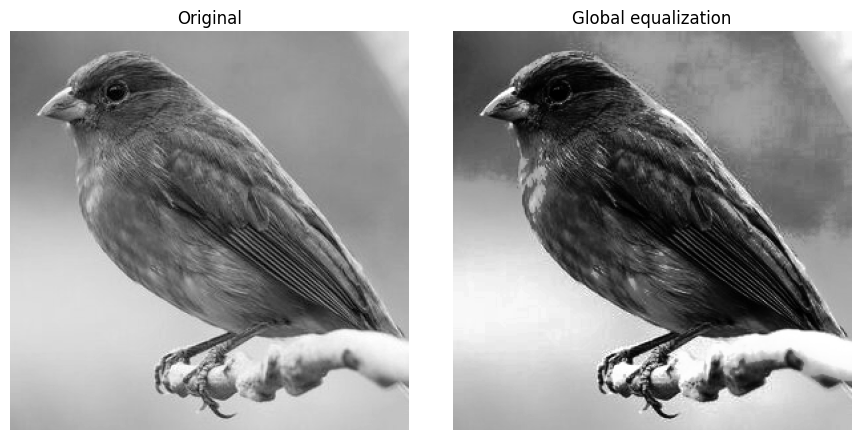

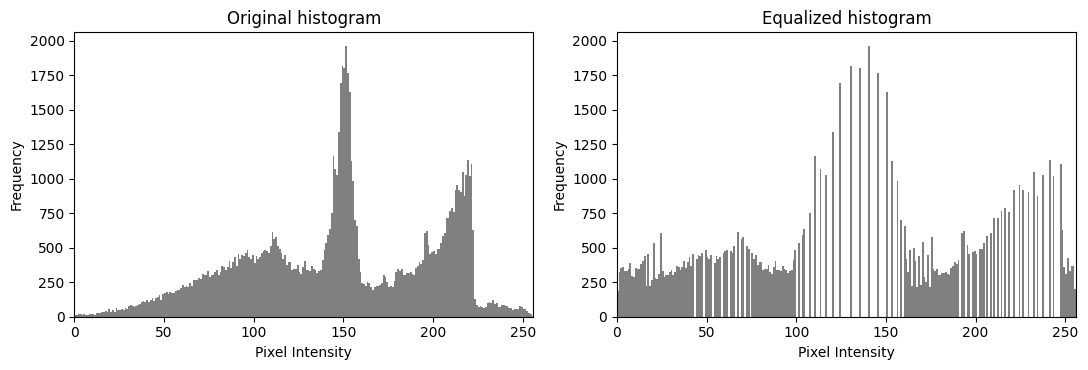

Original  : min 0 max 255 std 52.35
Equalized : min 0 max 255 std 73.82
Flat dark patch, mean -> original: nan | equalized: nan
Noise (std) in that patch -> original: nan | equalized: nan
Original  upper-left mean= 112.5  lower-right mean=   nan
Equalized upper-left mean=  76.7  lower-right mean=   nan


/var/folders/kl/zw1d72g13lb8jc92z00pgpr00000gn/T/ipykernel_16300/2978381252.py:12: RuntimeWarning: Mean of empty slice.
  print("Flat dark patch, mean -> original:", round(float(img[patch].mean()), 1), "| equalized:", round(float(equalized[patch].mean()), 1))
/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)
/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/numpy/core/_methods.py:265: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/numpy/core/_methods.py:223: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean, casting='unsafe',
/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/numpy/core/_m

In [19]:
equalized = cv.equalizeHist(img)
show_pair([img, equalized], ["Original", "Global equalization"], figsize=(9, 4.4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, pic, name in zip(axes, [img, equalized], ["Original histogram", "Equalized histogram"]):
    ax.hist(pic.ravel(), bins=256, range=(0, 256), color="gray")
    ax.set_title(name); ax.set_xlabel("Pixel Intensity"); ax.set_ylabel("Frequency"); ax.set_xlim(0, 256)
plt.tight_layout(); plt.show()
print("Original  : min", img.min(), "max", img.max(), "std", round(img.std(), 2))
print("Equalized : min", equalized.min(), "max", equalized.max(), "std", round(equalized.std(), 2))
# Noise estimate in a flat, dark paper patch (lower middle of the page)
patch = (slice(440, 470), slice(230, 260))
print("Flat dark patch, mean -> original:", round(float(img[patch].mean()), 1), "| equalized:", round(float(equalized[patch].mean()), 1))
print("Noise (std) in that patch -> original:", round(float(img[patch].std()), 2),
      "| equalized:", round(float(equalized[patch].std()), 2))
for name, pic in [("Original", img), ("Equalized", equalized)]:
    print(f"{name:9s} upper-left mean={pic[0:128, 0:128].mean():6.1f}  lower-right mean={pic[384:512, 384:512].mean():6.1f}")

**Discussion:** equalization stretches the intensities over the full 0–255 range, so the overall contrast and the text become crisper. Detail does not improve everywhere, though: one global mapping brightens the already-bright upper-left corner towards white and makes the dark lower-right corner darker, so lighting differences get stronger. Noise is also amplified, shown by the higher standard deviation in the flat dark patch.

## 8. CLAHE (clipLimit = 2.0, tileGridSize = (8, 8))

**Dry run** — four-bin histogram `[6, 2, 0, 0]`, absolute bin cap = 4 (simplified model).

In [20]:
h = np.array([6.0, 2.0, 0.0, 0.0]); cap = 4
clipped = np.minimum(h, cap)
excess = (h - clipped).sum()
add = excess / len(h)
new_h = clipped + add
cdf_old = np.cumsum(h) / h.sum()
cdf_new = np.cumsum(new_h) / new_h.sum()
print("Original histogram :", h, "total", h.sum())
print("After clipping at 4:", clipped, "| excess =", excess)
print("Excess per bin     :", add)
print("After redistribution:", new_h, "total", new_h.sum())
print("Cumulative counts   :", np.cumsum(new_h))
print("New CDF             :", np.round(cdf_new, 4))
print("Old CDF (no clip)   :", np.round(cdf_old, 4))
print("Mapping to 0-3 range (3 x CDF):", np.round(3 * cdf_new, 4), "  [old:", np.round(3 * cdf_old, 4), "]")

Original histogram : [6. 2. 0. 0.] total 8.0
After clipping at 4: [4. 2. 0. 0.] | excess = 2.0
Excess per bin     : 0.5
After redistribution: [4.5 2.5 0.5 0.5] total 8.0
Cumulative counts   : [4.5 7.  7.5 8. ]
New CDF             : [0.5625 0.875  0.9375 1.    ]
Old CDF (no clip)   : [0.75 1.   1.   1.  ]
Mapping to 0-3 range (3 x CDF): [1.6875 2.625  2.8125 3.    ]   [old: [2.25 3.   3.   3.  ] ]


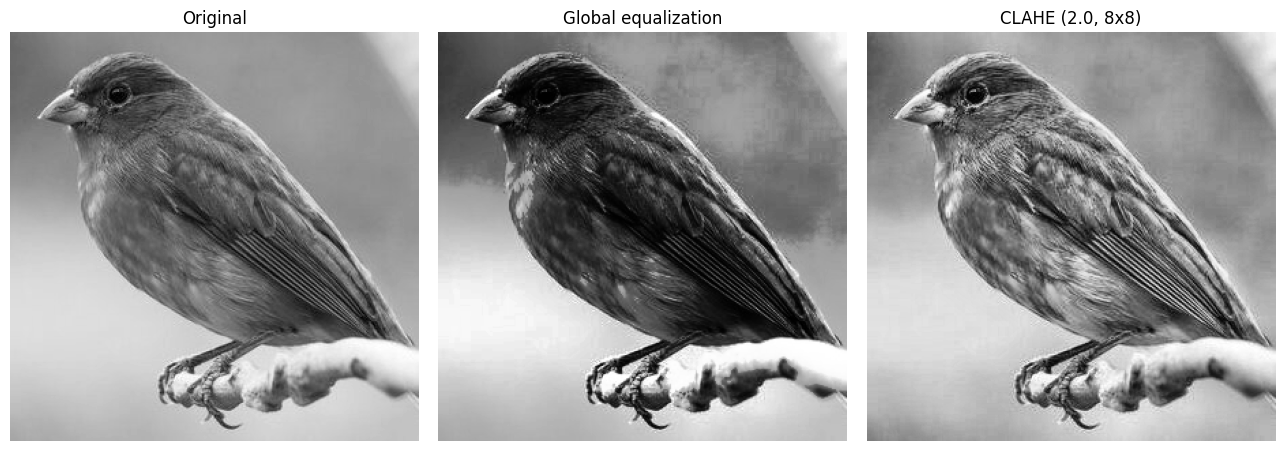

tileGridSize=(8, 8) means 8 x 8 = 64 tiles; each tile is about 37 x 37 pixels for this image.
Original   upper-left mean= 112.5 lower-right mean=   nan  difference=   nan
Global HE  upper-left mean=  76.7 lower-right mean=   nan  difference=   nan
CLAHE      upper-left mean= 124.7 lower-right mean=   nan  difference=   nan


/var/folders/kl/zw1d72g13lb8jc92z00pgpr00000gn/T/ipykernel_16300/2832568912.py:9: RuntimeWarning: Mean of empty slice.
  print(f"{name:10s} upper-left mean={ul.mean():6.1f} lower-right mean={lr.mean():6.1f}  difference={ul.mean() - lr.mean():6.1f}")


In [21]:
clahe = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
local = clahe.apply(img)
show_pair([img, equalized, local], ["Original", "Global equalization", "CLAHE (2.0, 8x8)"], figsize=(13, 4.4))
th, tw = img.shape[0] // 8, img.shape[1] // 8
print("tileGridSize=(8, 8) means 8 x 8 =", 8 * 8, "tiles; each tile is about", th, "x", tw, "pixels for this image.")
# Compare the dark lower-right corner against the bright upper-left corner
for name, pic in [("Original", img), ("Global HE", equalized), ("CLAHE", local)]:
    ul = pic[0:128, 0:128]; lr = pic[384:512, 384:512]
    print(f"{name:10s} upper-left mean={ul.mean():6.1f} lower-right mean={lr.mean():6.1f}  difference={ul.mean() - lr.mean():6.1f}")

**Why interpolation is needed:** each tile has its own mapping, so two neighbouring tiles would map the same intensity to different outputs and a visible seam would appear along the tile border. CLAHE therefore blends (bilinearly interpolates) the mappings of neighbouring tiles for every pixel.

## 9. Fixed binary thresholding (T = 127)

**Dry run** — pixels `[0, 80, 127, 128, 180, 255]`, rule: output 255 if r > T else 0.

In [22]:
t_px = np.array([0, 80, 127, 128, 180, 255], dtype=np.uint8)
for T in (127, 180):
    out = np.where(t_px > T, 255, 0).astype(np.uint8)
    print(f"T = {T}")
    table(["r", f"r > {T}?", "output"], [[r, "True" if r > T else "False", o] for r, o in zip(t_px, out)])
    cv_out = cv.threshold(t_px.reshape(2, 3), T, 255, cv.THRESH_BINARY)[1].ravel()
    print("White pixels:", int((out == 255).sum()), "| matches OpenCV:", np.array_equal(out, cv_out), "\n")

T = 127
  r | r > 127? | output
----+----------+-------
  0 |    False |      0
 80 |    False |      0
127 |    False |      0
128 |     True |    255
180 |     True |    255
255 |     True |    255
White pixels: 3 | matches OpenCV: True 

T = 180
  r | r > 180? | output
----+----------+-------
  0 |    False |      0
 80 |    False |      0
127 |    False |      0
128 |    False |      0
180 |    False |      0
255 |     True |    255
White pixels: 1 | matches OpenCV: True 



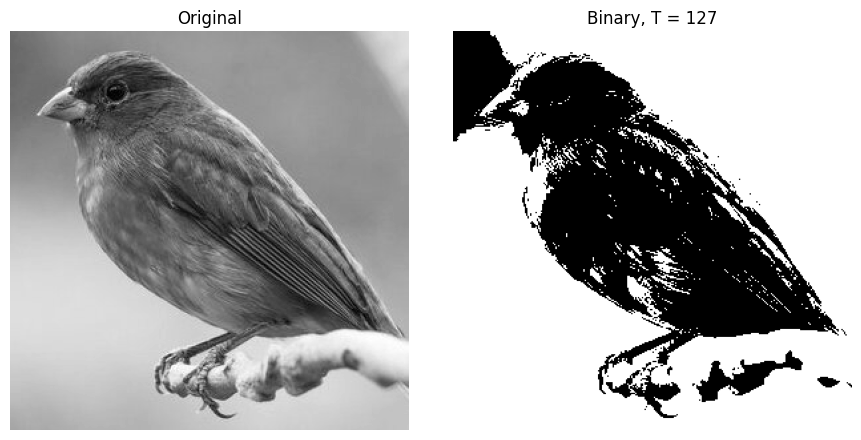

Threshold used: 127.0
Unique values in the binary image: [  0 255]
White pixels: 59251 (65.83 %)


In [23]:
T_used, binary = cv.threshold(img, 127, 255, cv.THRESH_BINARY)
show_pair([img, binary], ["Original", f"Binary, T = {int(T_used)}"], figsize=(9, 4.4))
print("Threshold used:", T_used)
print("Unique values in the binary image:", np.unique(binary))
print("White pixels:", int((binary == 255).sum()), f"({100 * (binary == 255).mean():.2f} %)")

## 10. Otsu thresholding

**Dry run** — pixels `[0, 1, 4, 5]`, test T = 0..4 with classes r ≤ T and r > T, between-class score w0·w1·(μ0 − μ1)².

In [24]:
o_px = np.array([0, 1, 4, 5], dtype=np.uint8)
rows, scores = [], {}
for T in range(0, 5):
    c0 = o_px[o_px <= T]; c1 = o_px[o_px > T]
    w0, w1 = len(c0) / len(o_px), len(c1) / len(o_px)
    mu0, mu1 = c0.mean(), c1.mean()
    sc = w0 * w1 * (mu0 - mu1) ** 2
    scores[T] = sc
    rows.append([T, c0.tolist(), c1.tolist(), w0, w1, round(mu0, 4), round(mu1, 4), round(sc, 4)])
table(["T", "class0 (r<=T)", "class1 (r>T)", "w0", "w1", "mu0", "mu1", "w0*w1*(mu0-mu1)^2"], rows)
best = max(scores.values())
T_best = min(T for T, v in scores.items() if abs(v - best) < 1e-12)     # smallest T among ties
print("\nMaximum score:", best, "| tied at T =", [T for T, v in scores.items() if abs(v - best) < 1e-12], "-> chosen T =", T_best)
pred = np.where(o_px > T_best, 255, 0)
print("Predicted mask:", pred.tolist())
cv_T, cv_mask = cv.threshold(o_px.reshape(2, 2), 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print("OpenCV Otsu threshold:", cv_T, "| OpenCV mask:", cv_mask.ravel().tolist(), "| matches prediction:", cv_mask.ravel().tolist() == pred.tolist())

T | class0 (r<=T) | class1 (r>T) |   w0 |   w1 |    mu0 |    mu1 | w0*w1*(mu0-mu1)^2
--+---------------+--------------+------+------+--------+--------+------------------
0 |           [0] |    [1, 4, 5] | 0.25 | 0.75 |    0.0 | 3.3333 |            2.0833
1 |        [0, 1] |       [4, 5] |  0.5 |  0.5 |    0.5 |    4.5 |               4.0
2 |        [0, 1] |       [4, 5] |  0.5 |  0.5 |    0.5 |    4.5 |               4.0
3 |        [0, 1] |       [4, 5] |  0.5 |  0.5 |    0.5 |    4.5 |               4.0
4 |     [0, 1, 4] |          [5] | 0.75 | 0.25 | 1.6667 |    5.0 |            2.0833

Maximum score: 4.0 | tied at T = [1, 2, 3] -> chosen T = 1
Predicted mask: [0, 0, 255, 255]
OpenCV Otsu threshold: 1.0 | OpenCV mask: [0, 0, 255, 255] | matches prediction: True


Otsu threshold returned by OpenCV: 135.0


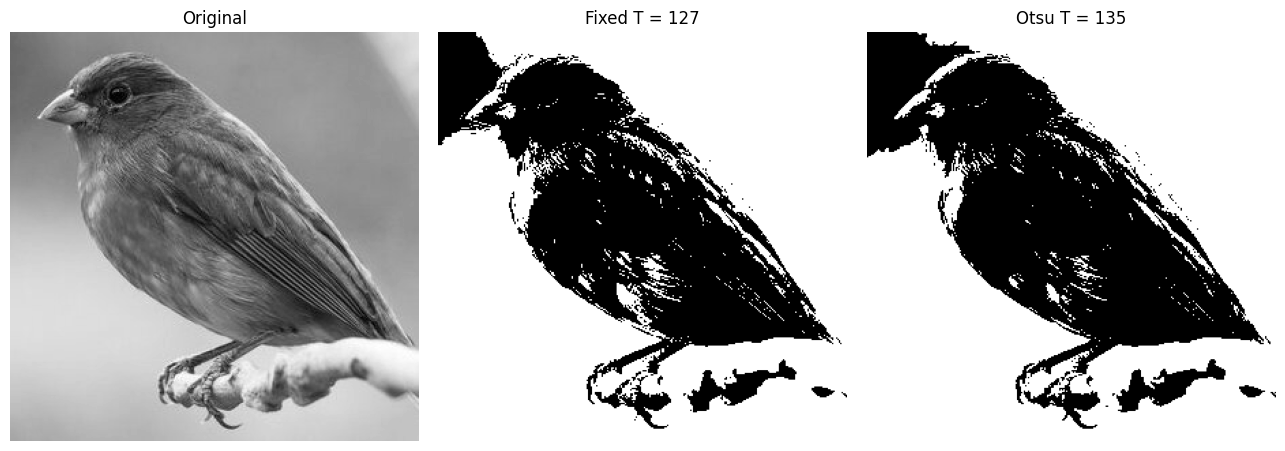

Pixels where the fixed and Otsu masks differ: 2788 (3.10 %)


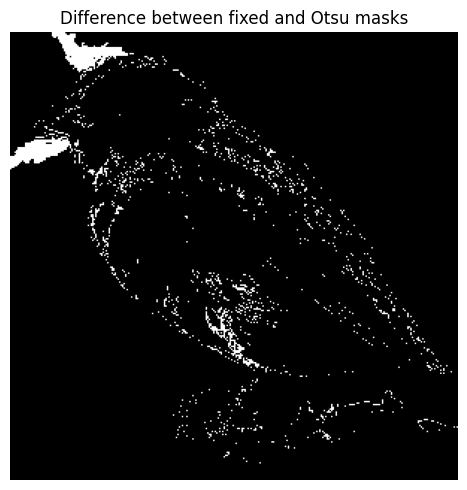

In [25]:
otsu_T, otsu = cv.threshold(img, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print("Otsu threshold returned by OpenCV:", otsu_T)
show_pair([img, binary, otsu], ["Original", "Fixed T = 127", f"Otsu T = {int(otsu_T)}"], figsize=(13, 4.4))
diff = (binary != otsu)
print("Pixels where the fixed and Otsu masks differ:", int(diff.sum()), f"({100 * diff.mean():.2f} %)")
show_pair([diff.astype(np.uint8) * 255], ["Difference between fixed and Otsu masks"], figsize=(5, 5))

## 11. Adaptive Gaussian thresholding (blockSize = 11, C = 2)

**Dry run** — 3 × 3 neighbourhood with Gaussian weights `[[1,2,1],[2,4,2],[1,2,1]]/16`, T = mean − 2.

In [26]:
nb_ = np.array([[100, 100, 100], [100, 120, 140], [140, 140, 140]], dtype=np.float64)
wts = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float64) / 16
terms = nb_ * wts * 16
print("pixel x weight(x16):\n", terms.astype(int))
wsum = terms.sum()
mean = (nb_ * wts).sum()
T_loc = mean - 2
print("Sum of weighted terms =", wsum, "-> weighted mean =", wsum, "/ 16 =", mean)
print("T = mean - C =", mean, "- 2 =", T_loc)
centre = nb_[1, 1]
print(f"Centre pixel {centre:.0f} > {T_loc:.0f}?", centre > T_loc, "->", 255 if centre > T_loc else 0)
print(f"A pixel equal to T ({T_loc:.0f}) > {T_loc:.0f}?", T_loc > T_loc, "->", 0)
# OpenCV check on the same 3x3 patch (blockSize=3 so the whole patch is the neighbourhood)
cv_ad = cv.adaptiveThreshold(nb_.astype(np.uint8), 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 3, 2)
print("OpenCV centre output:", cv_ad[1, 1])

pixel x weight(x16):
 [[100 200 100]
 [200 480 280]
 [140 280 140]]
Sum of weighted terms = 1920.0 -> weighted mean = 1920.0 / 16 = 120.0
T = mean - C = 120.0 - 2 = 118.0
Centre pixel 120 > 118? True -> 255
A pixel equal to T (118) > 118? False -> 0
OpenCV centre output: 255


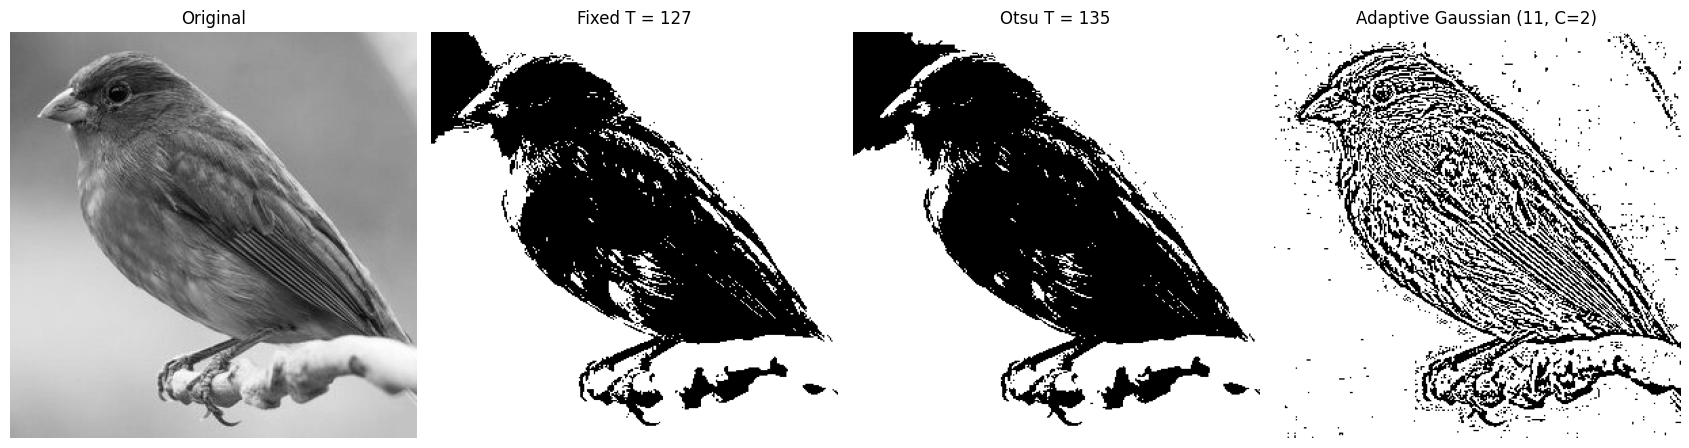

Fixed     white pixels overall:  65.83 %   in dark lower-right corner:    nan %
Otsu      white pixels overall:  62.74 %   in dark lower-right corner:    nan %
Adaptive  white pixels overall:  77.51 %   in dark lower-right corner:    nan %


/var/folders/kl/zw1d72g13lb8jc92z00pgpr00000gn/T/ipykernel_16300/2066272915.py:6: RuntimeWarning: Mean of empty slice.
  print(f"{name:9s} white pixels overall: {100 * (m == 255).mean():6.2f} %   in dark lower-right corner: {100 * (ll == 255).mean():6.2f} %")


In [27]:
adaptive = cv.adaptiveThreshold(img, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)
show_pair([img, binary, otsu, adaptive],
          ["Original", "Fixed T = 127", f"Otsu T = {int(otsu_T)}", "Adaptive Gaussian (11, C=2)"], figsize=(17, 4.4))
for name, m in [("Fixed", binary), ("Otsu", otsu), ("Adaptive", adaptive)]:
    ll = m[384:512, 384:512]
    print(f"{name:9s} white pixels overall: {100 * (m == 255).mean():6.2f} %   in dark lower-right corner: {100 * (ll == 255).mean():6.2f} %")

**When local thresholds help:** when lighting is uneven (shadowed documents, gradients), a single global value either loses the dark side or floods the bright side; a local threshold is computed from each pixel's neighbourhood and so follows the illumination. On evenly lit images with a clear two-peak histogram, Otsu is simpler and less noisy.

## Summary of key concepts

* **Overflow / wrap-around:** `uint8` arithmetic wraps modulo 256 (for example 240 + 40 = 280 → 24). Using `int16` / `float32` for the calculation avoids it.
* **Clipping:** `np.clip(..., 0, 255)` forces out-of-range results to the limits (saturation) before converting back to `uint8`; detail in clipped regions is lost.
* **Brightness vs contrast:** brightness adds a constant (shifts every pixel); contrast multiplies (changes the distance between pixels, here around the pivot 128).
* **Gamma convention used here:** s = 255(r/255)^γ, so γ < 1 brightens and γ > 1 darkens; 0 and 255 never change.
* **Global vs local:** global equalization/thresholds suit evenly lit images; CLAHE and adaptive thresholds suit uneven lighting.